# Computer Vision - Assignment 1: Fine Detail and the Big Picture

**Run-only notebook.** All the real code lives in the `.py` files next to this notebook (`conv.py`, `edges.py`, `filters.py`, `freq.py`, `pyramids.py`, `blend.py`, `seam.py` and the `run_*.py` scripts). This notebook only imports and runs them, then displays the figures they save in `../results`.

**Folder layout expected**
```
code/      <- this notebook + all .py files (+ tests/)
images/    part1_filters/  part2_frequencies/  part3_seams/   (starter pack)
           own/            <- YOUR images (names listed in section 0)
results/   <- created automatically
```
Run the cells top to bottom. Every section can be switched off in the settings cell. Sections that need your own images (marked **OWN**) are skipped with a message until the files and coordinates exist.

## 0. Settings and helpers

In [ ]:
import os, sys, runpy, subprocess, shutil
import numpy as np, cv2
from IPython.display import Image, display
sys.path.insert(0, os.getcwd())

IMG, RES = "../images", "../results"
OWN = IMG + "/own"                       # put YOUR images here (<= 1000 px on the longer side)
os.makedirs(RES, exist_ok=True); os.makedirs(OWN, exist_ok=True)

# ---- switches: set to False to skip a section (1.1 and 3.x are the slow ones) ----
RUN = dict(tests=False, bench_1_1=True, edges_1_2_1_3=True, hybrids_2_1=True, aliasing_2_2=True,
           pyramids_2_3=True, blends_2_4=True, seams_3_1=True, compare_3_2=True, bonus=True)

# ---- name of each own image (change them here if you use other file names) ----
OWN_FILES = dict(
    hybrid1_low=OWN+"/hybrid1_low.jpg",  hybrid1_high=OWN+"/hybrid1_high.jpg",
    hybrid2_low=OWN+"/hybrid2_low.jpg",  hybrid2_high=OWN+"/hybrid2_high.jpg",
    blend1_base=OWN+"/blend1_base.jpg",  blend1_obj=OWN+"/blend1_obj.jpg",
    blend2_base=OWN+"/blend2_base.jpg",  blend2_obj=OWN+"/blend2_obj.jpg",
    seam_person=OWN+"/seam_person.jpg",  seam_landscape=OWN+"/seam_landscape.jpg", seam_fail=OWN+"/seam_fail.jpg",
    bonus_photo=OWN+"/bonus_photo.jpg",
)

def show_png(*names, width=None):
    """Display figures saved by the scripts (names relative to ../results, or full paths)."""
    for n in names:
        p = n if os.path.exists(n) else f"{RES}/{n}"
        if os.path.exists(p): display(Image(filename=p, width=width))
        else: print("missing figure:", p)

def have(*paths):
    miss = [p for p in paths if not os.path.exists(p)]
    if miss: print("SKIPPED - file(s) not found:", miss)
    return not miss

def run_script(name, *args):
    """Run one of the run_*.py scripts from this folder (they use ../images and ../results)."""
    old = sys.argv; sys.argv = [name, *map(str, args)]
    try: runpy.run_path(name)
    finally: sys.argv = old

def shrink_own_images(max_side=1000):
    """Resize every image in ../images/own so its longer side is <= max_side (originals backed up in ../images/own_original)."""
    bak = IMG + "/own_original"; os.makedirs(bak, exist_ok=True)
    for f in sorted(os.listdir(OWN)):
        if not f.lower().endswith((".jpg", ".jpeg", ".png")): continue
        p = f"{OWN}/{f}"; im = cv2.imread(p)
        if im is None: continue
        s = max(im.shape[:2])
        if s > max_side:
            if not os.path.exists(f"{bak}/{f}"): shutil.copy(p, f"{bak}/{f}")
            im = cv2.resize(im, None, fx=max_side/s, fy=max_side/s, interpolation=cv2.INTER_AREA)
            cv2.imwrite(p, im); print(f"{f}: shrunk to {im.shape[1]}x{im.shape[0]}")
        else:
            print(f"{f}: {im.shape[1]}x{im.shape[0]} (ok)")

def grid(path, step=20):
    """Show an image with a pixel grid so you can read (x, y) coordinates for the alignment points / mask polygons."""
    get_ipython().run_line_magic("matplotlib", "inline")
    from align_images import show_with_grid
    from utils import load_image
    show_with_grid(load_image(path), step)

**Own image names** (put these files in `../images/own/`):

| file | use |
|---|---|
| `hybrid1_low.jpg`, `hybrid1_high.jpg` | 2.1 hybrid pair 1 (low-pass image, high-pass image) |
| `hybrid2_low.jpg`, `hybrid2_high.jpg` | 2.1 hybrid pair 2 (this one may fail - explain why) |
| `blend1_base.jpg`, `blend1_obj.jpg` | 2.4 blend 1 (background, object pasted on it) |
| `blend2_base.jpg`, `blend2_obj.jpg` | 2.4 blend 2 (clouds background, kite pasted on it) |
| `seam_person.jpg`, `seam_landscape.jpg`, `seam_fail.jpg` | 3.2 (one shows a person, one is the failure case) |
| `bonus_photo.jpg` | Bonus (object removal + enlargement) |

Run the next cell once after copying the files to shrink anything bigger than 1000 px.

In [ ]:
shrink_own_images()

blend1_base.jpg: 600x600 (ok)
blend1_obj.jpg: 750x1000 (ok)
blend2_base.jpg: 512x512 (ok)
blend2_obj.jpg: 540x360 (ok)
bonus_photo.jpg: 612x459 (ok)
hybrid1_high.jpg: 750x1000 (ok)
hybrid1_low.jpg: 750x1000 (ok)
hybrid2_high.jpg: 540x360 (ok)
hybrid2_low.jpg: 750x1000 (ok)
seam_fail.jpg: 1000x562 (ok)
seam_landscape.jpg: 626x468 (ok)
seam_person.jpg: 612x407 (ok)


### Reading coordinates (needed for alignment points and mask polygons)
Change `path`, run, and read (x, y) off the grid. Use the **same two features** (e.g. both eyes) on both images of a pair.

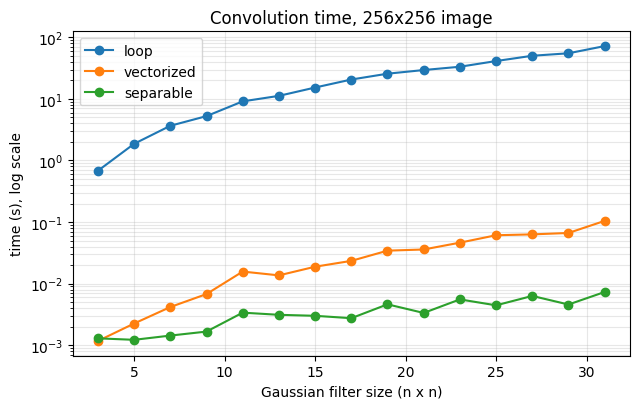

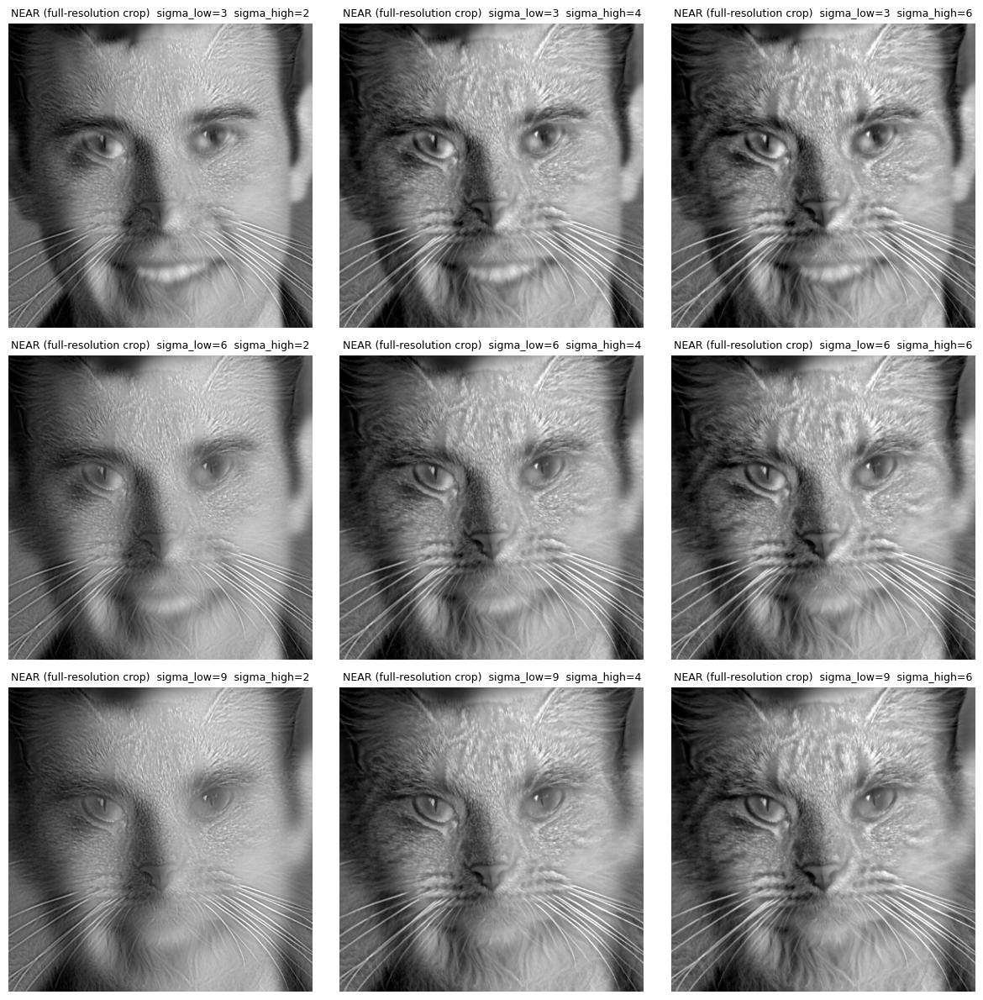

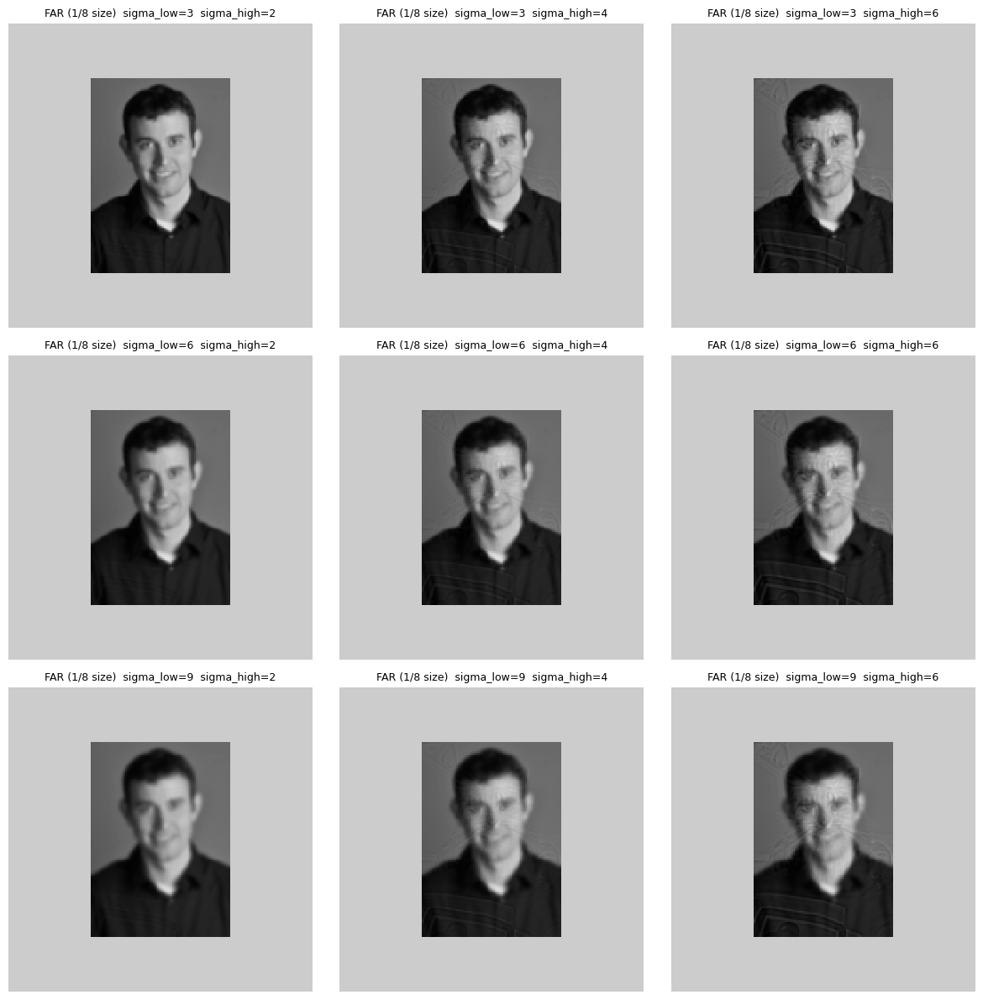

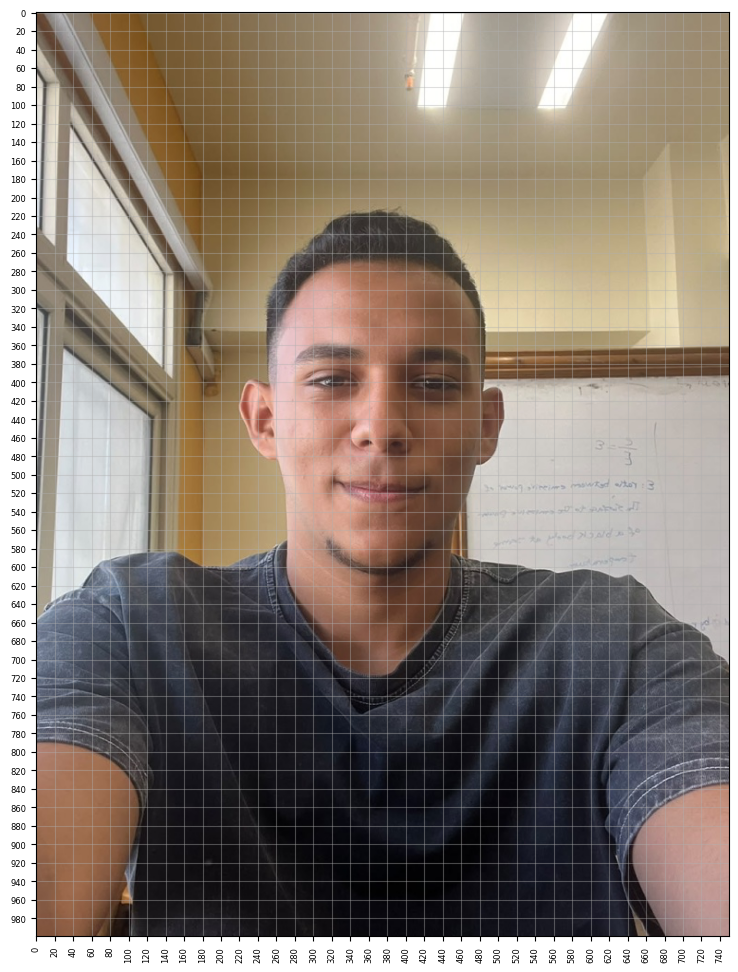

In [ ]:
path = OWN_FILES["hybrid1_low"]
if have(path): grid(path)

## Tests (optional)
Runs the unit tests in `tests/` (if you kept that folder). Set `RUN['tests']=True` in the settings cell.

In [ ]:
if RUN["tests"] and os.path.isdir("tests"):
    for t in sorted(f for f in os.listdir("tests") if f.startswith("test_")):
        r = subprocess.run([sys.executable, f"tests/{t}"], capture_output=True, text=True)
        print(f"== {t}:", r.stdout.strip().splitlines()[-1] if r.stdout.strip() else r.stderr[-300:])

## Part 1 - Filters and Edges
### 1.1 Convolution from scratch: sanity check and timing
(The loop version is slow on big filters - this cell can take a few minutes.)

SANITY CHECK vs scipy.signal.convolve2d(mode='same'), 300 random cases
  kernels used: {'separable kernels': 157, 'non-separable kernels': 143}
  max |ours - scipy|  loop       : 3.55e-14
  max |ours - scipy|  vectorized : 3.55e-14
  max |ours - scipy|  separable  : 2.13e-14

TIMING on a 256x256 image (seconds; vectorized/separable = best of several repeats)
   size       loop   vectorized   separable  loop/vec  vec/sep
  3x3       0.8252      0.00113     0.00117       731      1.0
  5x5       2.1324      0.00255     0.00157       837      1.6
  7x7       3.7364      0.00443     0.00209       843      2.1
  9x9       6.1467      0.00737     0.00260       834      2.8
 11x11      8.9537      0.01024     0.00234       874      4.4
 13x13     13.1541      0.01532     0.00238       859      6.4
 15x15     16.6237      0.02154     0.00331       772      6.5
 17x17     21.9742      0.03223     0.00571       682      5.6
 19x19     25.9757      0.04821     0.00569       539      8.5
 21x21   

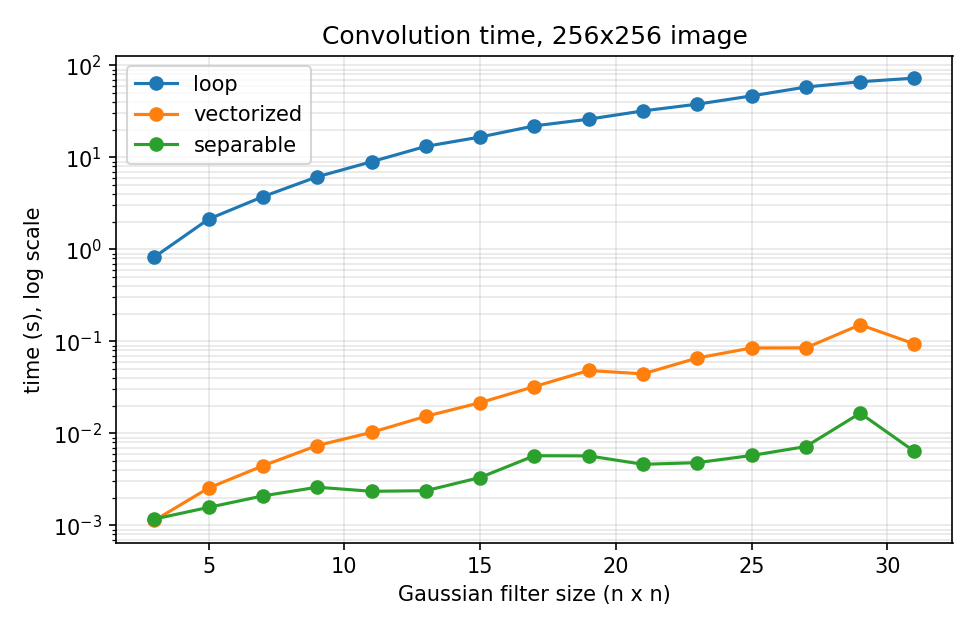

In [ ]:
if RUN["bench_1_1"]:
    run_script("run_1_1_benchmark.py")
    show_png("benchmark_1_1.png", width=700)

### 1.2 Finite differences and 1.3 Derivative of Gaussian

image: part1_filters/facade.png  shape=(670, 736)

[1.2] finite differences, zero padding
  gx range [-0.996, 0.988]  gy range [-0.918, 0.941]  mag max 1.232
  display scale: derivatives +-0.514 (99.5th pct of interior |g|), magnitude 0..0.626; arrays not modified
  threshold 0.25: 9.4% of all pixels, 8.9% of interior pixels are edges
  robust noise level of gx (MAD): 0.029  -> threshold is 8.6 x that level
  frame: mean magnitude on the 1-px border = 0.478 (zero pad) vs 0.041 (reflect); interior 0.090
         border pixels flagged as edges: 95.7% (zero pad) vs 1.8% (reflect)
         top row: corr(magnitude, image brightness) = 0.63

THRESHOLD SWEEP (share of pixels flagged as edges: whole image / interior)
  1.2  t=0.15:  18.6% /  18.0%
  1.2  t=0.25:   9.4% /   8.7%
  1.2  t=0.35:   4.8% /   4.3%
  1.2  t=0.45:   2.4% /   2.0%
  1.3  t=0.05:  24.3% /  22.6%
  1.3  t=0.08:  11.6% /  10.2%
  1.3  t=0.11:   5.7% /   4.6%
  1.3  t=0.15:   2.1% /   1.5%

[1.3] DoG, sigma = 2, filter siz

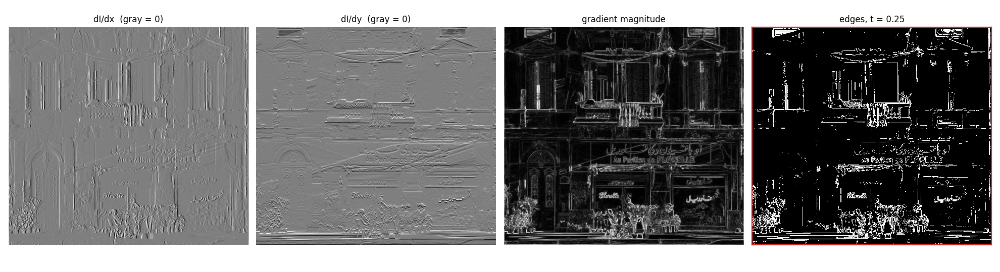

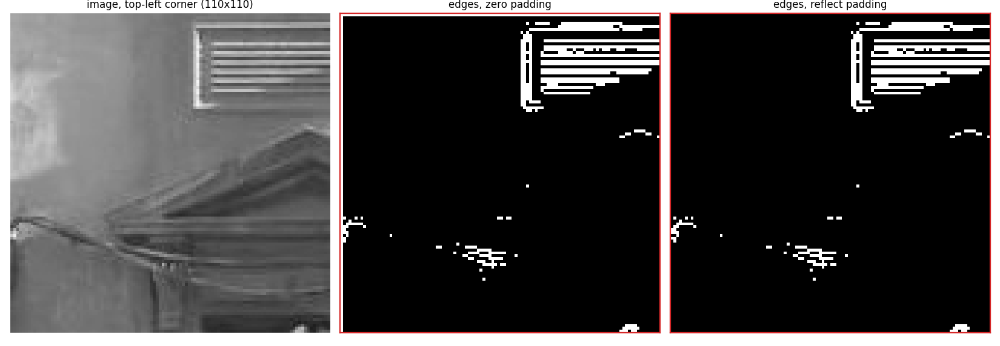

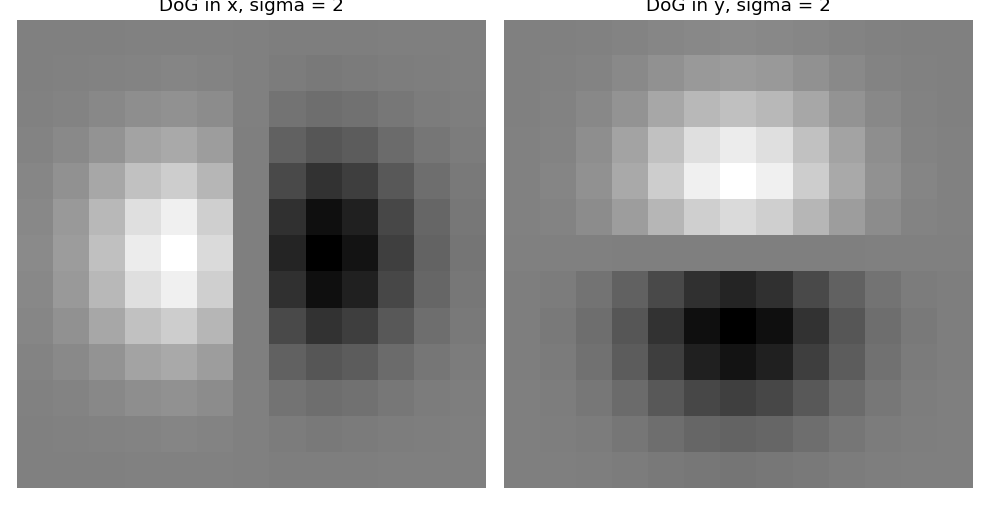

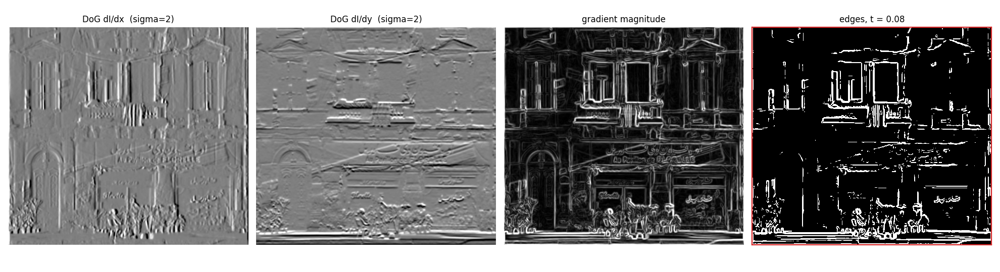

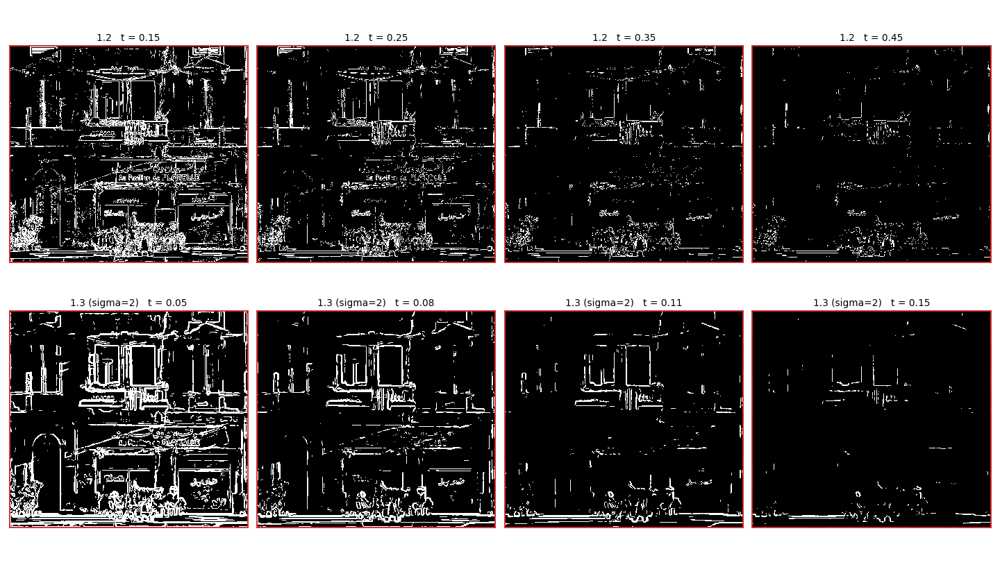

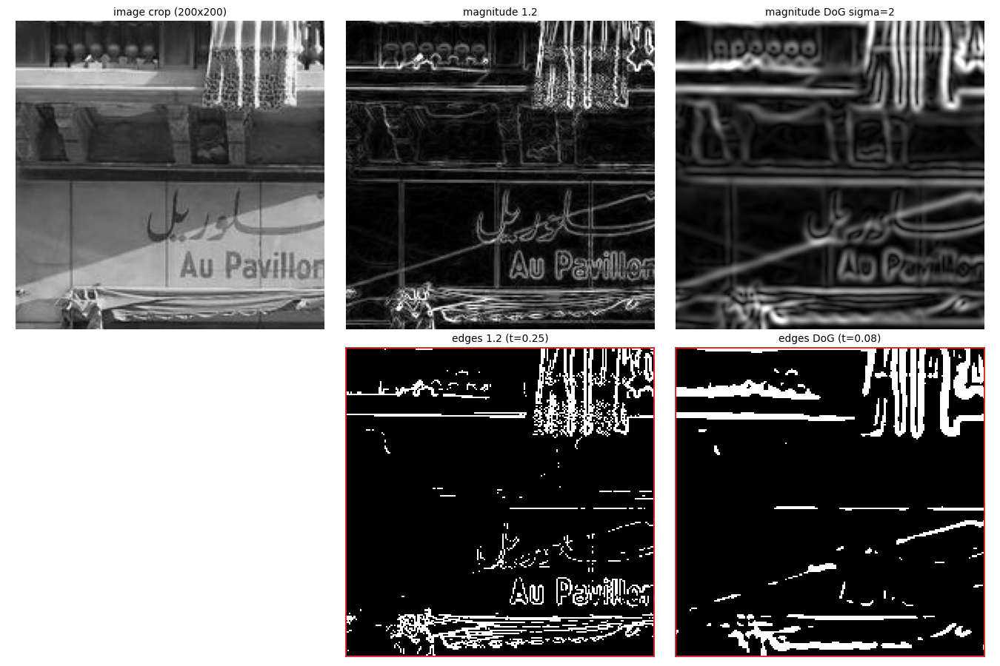

In [ ]:
if RUN["edges_1_2_1_3"] and have(IMG + "/part1_filters/facade.png"):
    run_script("run_1_2_1_3.py")
    show_png("fig_1_2_maps.png", "fig_1_2_frame_corner.png", "fig_1_3_dog_filters.png", "fig_1_3_maps.png",
             "fig_1_threshold_sweep.png", "fig_1_2_vs_1_3_crop.png")

## Part 2 - Frequencies, Pyramids and Blending
### 2.1 Hybrid images
Each entry: `low` supplies the low frequencies, `high` the high frequencies (it is warped onto `low`). `pts_*` are two matching (x, y) points. Fill the **OWN** entries (use `grid(...)` above), tune the sigmas, and report them.

[man_cat] sigma_low=6 (half-amplitude cutoff 0.0312 cyc/px), sigma_high=4 (cutoff 0.0468 cyc/px)
[man_cat] hybrid range [-0.205, 1.277]; 1.47% of pixels clipped for display/saving


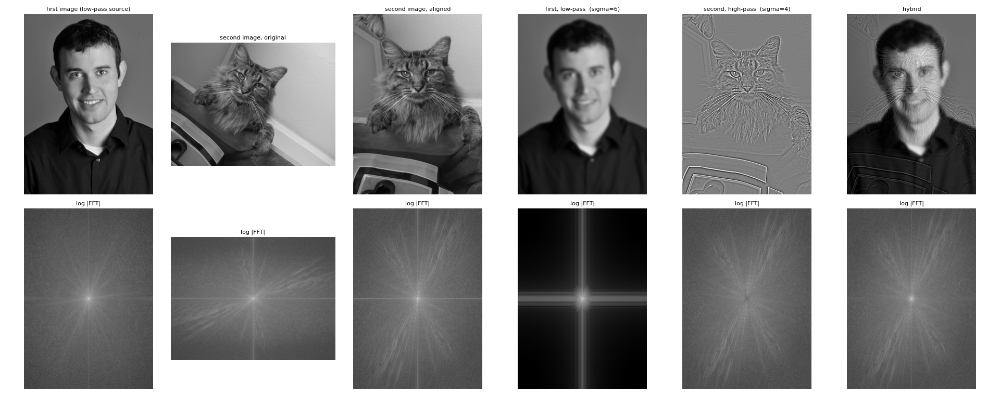

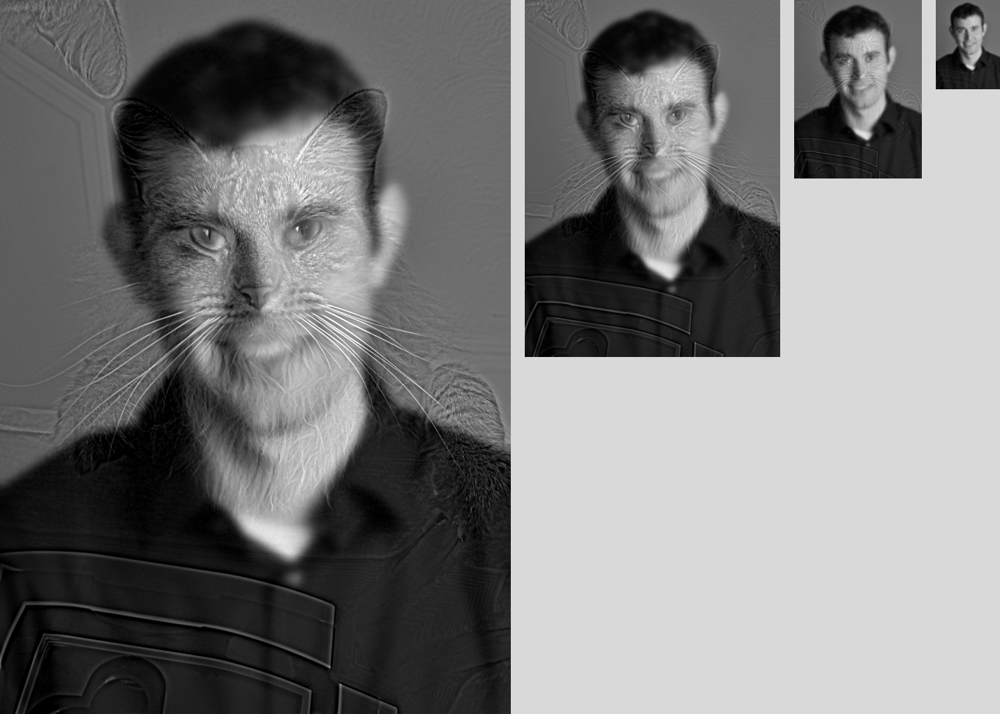

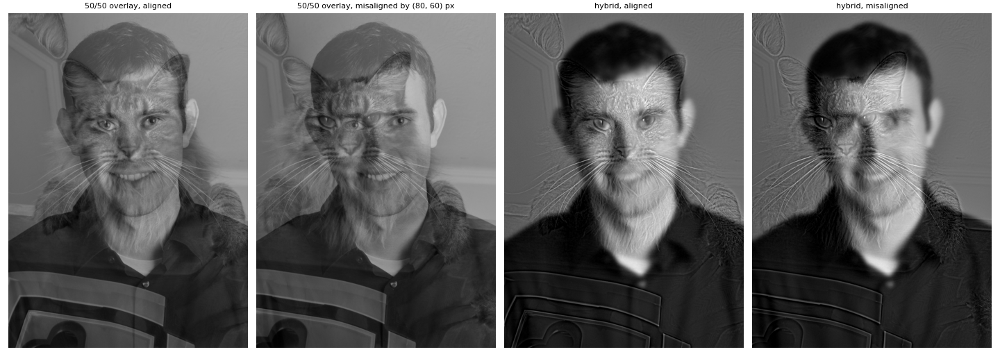

[own1] sigma_low=8 (half-amplitude cutoff 0.0234 cyc/px), sigma_high=3 (cutoff 0.0625 cyc/px)
[own1] hybrid range [-0.066, 0.981]; 0.01% of pixels clipped for display/saving


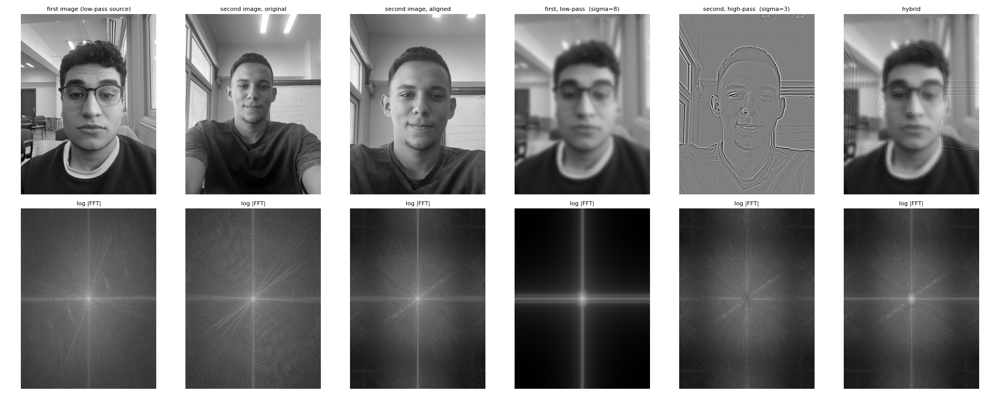

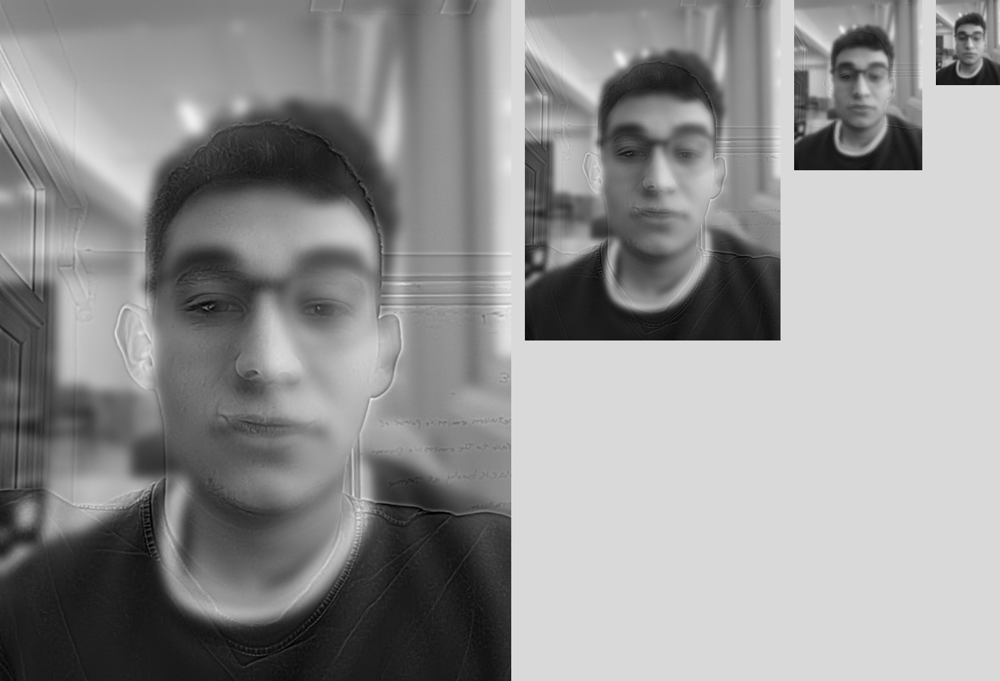

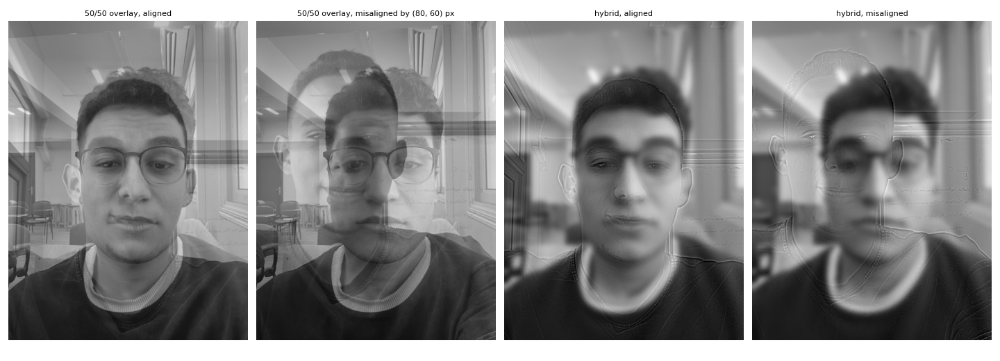

[own2] sigma_low=6 (half-amplitude cutoff 0.0312 cyc/px), sigma_high=3 (cutoff 0.0625 cyc/px)
[own2] hybrid range [-0.151, 1.453]; 17.49% of pixels clipped for display/saving


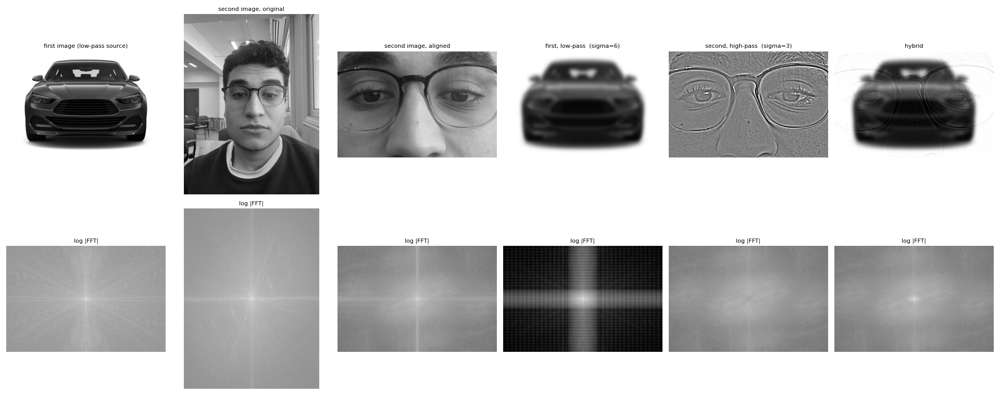

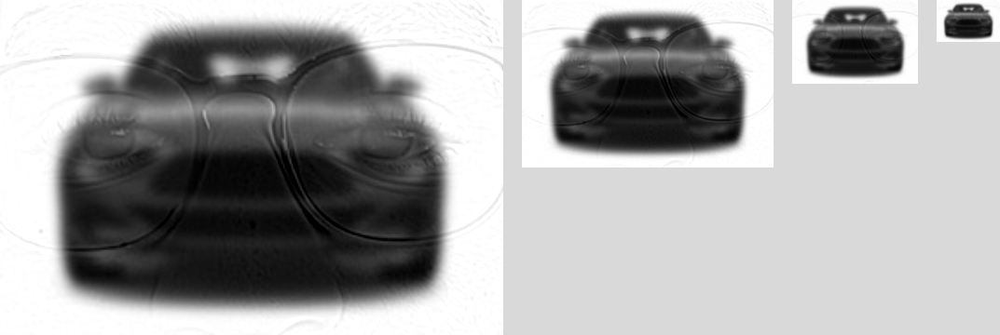

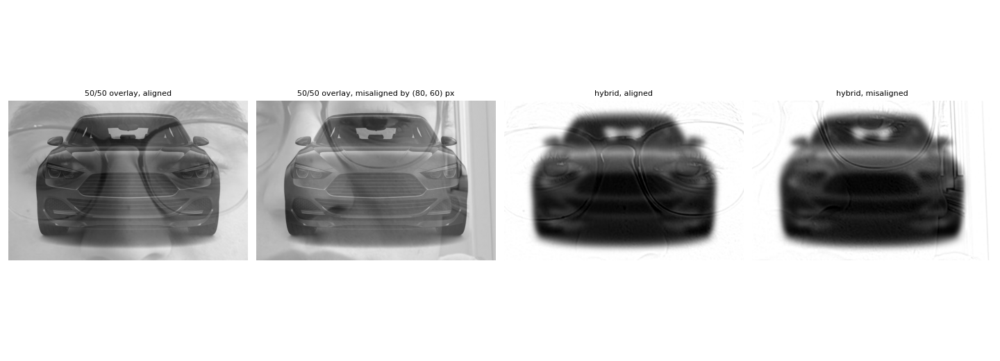

In [ ]:
from run_2_1_hybrid import process_pair
D2 = IMG + "/part2_frequencies/"
HYBRIDS = [
    dict(name="man_cat", low=D2+"hybrid_man.jpg", high=D2+"hybrid_cat.jpg",
         pts_low=[(299, 341), (443, 332)], pts_high=[(605, 290), (760, 372)], sigma_low=6, sigma_high=4),
    # OWN: fill pts_low / pts_high (two points each) and tune the sigmas
    # own1: LOW = the face with glasses (hybrid1_high.jpg, seen from far), HIGH = the other face (hybrid1_low.jpg, seen up close).
    #       (the roles are swapped on purpose: the HIGH image gets enlarged by align_images, so no empty borders appear)
    dict(name="own1", low=OWN_FILES["hybrid1_high"], high=OWN_FILES["hybrid1_low"],
         pts_low=[(310, 452), (477, 455)], pts_high=[(316, 401), (430, 402)], sigma_low=8, sigma_high=3),
    # own2: LOW = the car (hybrid2_high.jpg), HIGH = the face (hybrid2_low.jpg). The face matches the car's headlights (eyes <-> headlights).
    #       This is the pair that may fail: explain why in the report (the shapes do not match).
    dict(name="own2", low=OWN_FILES["hybrid2_high"], high=OWN_FILES["hybrid2_low"],
         pts_low=[(115, 158), (418, 158)], pts_high=[(310, 452), (477, 455)], sigma_low=6, sigma_high=3),
]
if RUN["hybrids_2_1"]:
    for h in HYBRIDS:
        if h["pts_low"] is None or h["pts_high"] is None:
            print(f"[{h['name']}] SKIPPED - set pts_low and pts_high first"); continue
        if not have(h["low"], h["high"]): continue
        process_pair(h["name"], h["low"], h["high"], h["pts_low"], h["pts_high"], h["sigma_low"], h["sigma_high"])
        show_png(f"fig_2_1_{h['name']}_process.png", f"fig_2_1_{h['name']}_distance.png", f"fig_2_1_{h['name']}_alignment.png")

#### 2.1 extra: how sigma_low / sigma_high were chosen (man + cat)

sigma -> half-amplitude cutoff of the Gaussian (cycles/pixel, period in pixels)
  sigma 2: 0.0937 cyc/px (period 10.7 px)
  sigma 3: 0.0625 cyc/px (period 16.0 px)
  sigma 4: 0.0468 cyc/px (period 21.3 px)
  sigma 6: 0.0312 cyc/px (period 32.0 px)
  sigma 9: 0.0208 cyc/px (period 48.0 px)

near = correlation of the hybrid's fine-detail band with the CAT's (want high) and the MAN's (want low)
far  = RMSE between the hybrid and the MAN / the CAT after shrinking to 1/8 with our reduce (want low / high)
s_low s_high | near~cat near~man | far RMSE man far RMSE cat
    4      2 |    0.959    0.040 |       0.0079       0.2633
    4      3 |    0.982    0.037 |       0.0093       0.2627
    4      4 |    0.990    0.036 |       0.0116       0.2620
    4      5 |    0.993    0.035 |       0.0144       0.2613
    6      2 |    0.962    0.016 |       0.0141       0.2619
    6      3 |    0.985    0.015 |       0.0150       0.2613
    6      4 |    0.993    0.015 |       0.0165       0.2606
    6  

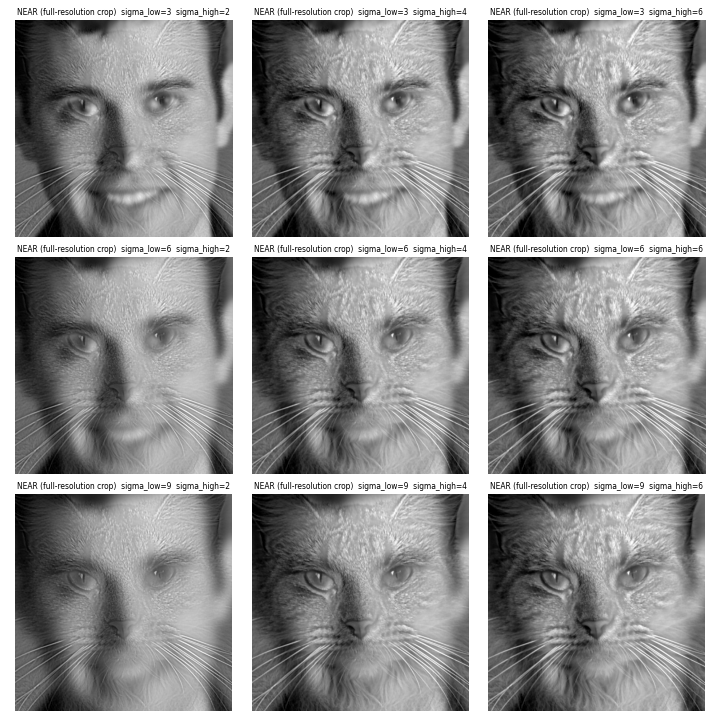

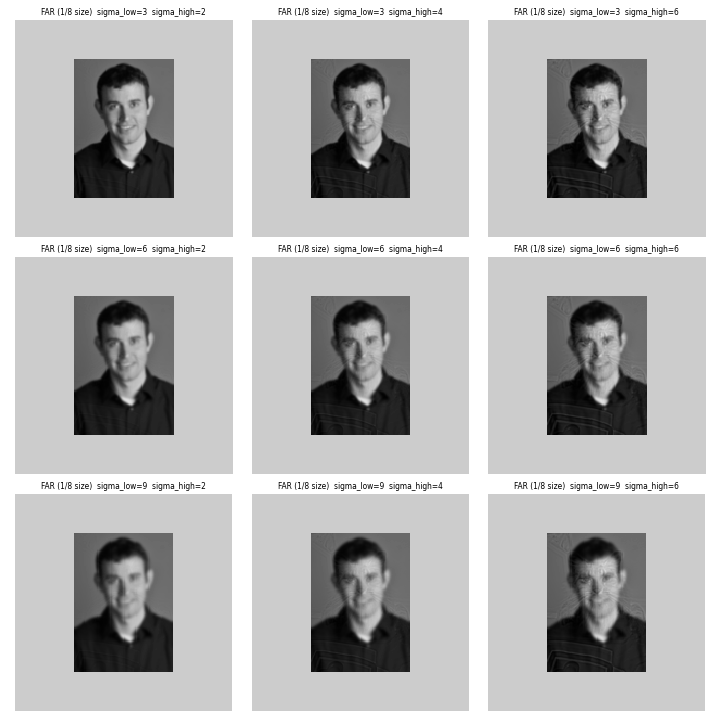

In [ ]:
if RUN["hybrids_2_1"] and have(IMG + "/part2_frequencies/hybrid_man.jpg", IMG + "/part2_frequencies/hybrid_cat.jpg"):
    run_script("run_2_1_sigma_sweep.py")
    show_png("fig_2_1_sigma_sweep_near.png", "fig_2_1_sigma_sweep_far.png")

### 2.2 Aliasing (rings.png)
First run without a chosen sigma to see the sweep, then set `SIGMA_ALIAS` to the smallest sigma with no false circles and run again for the side-by-side figure.

original (512, 512) -> shrunk (128, 128); region for the false-circle measure: 8284 px, where the ideal result has strength 0.1187
EXPERIMENT: strength of the false pattern (1.00 = full-amplitude rings, 0 = flat gray) and RMSE to the ideal result
 sigma  strength  RMSE vs ideal
  none     0.999         0.2873
   0.5     0.836         0.2453
  0.75     0.626         0.1916
   1.0     0.446         0.1483
  1.25     0.297         0.1181
   1.5     0.187         0.1060
  1.75     0.113         0.1085
   2.0     0.068         0.1182
  2.25     0.042         0.1300
   2.5     0.028         0.1413
   3.0     0.018         0.1594
   4.0     0.013         0.1803
saved side-by-side for sigma=2.5


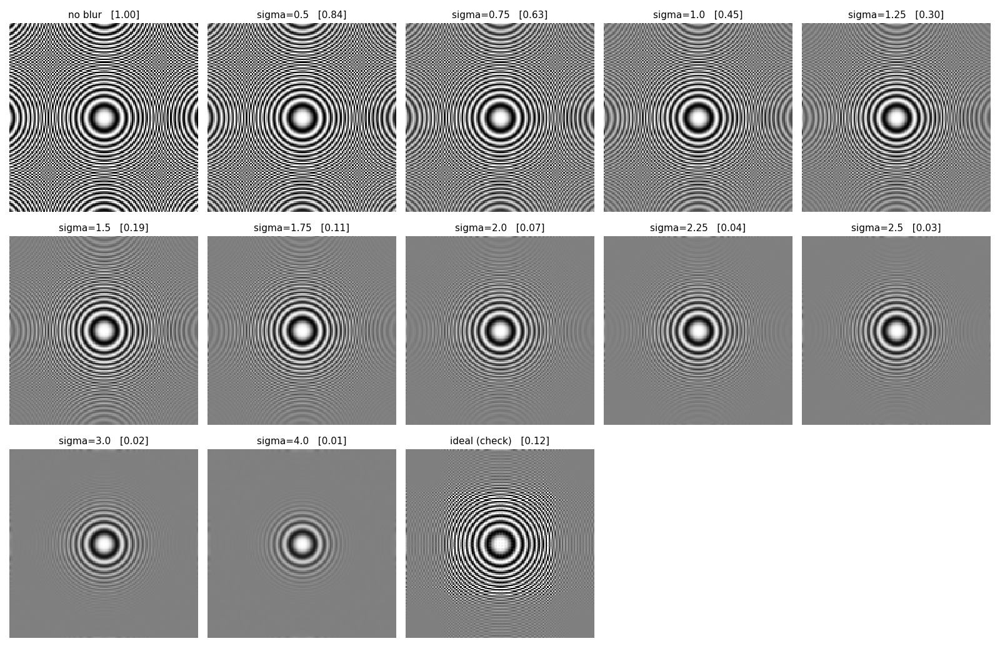

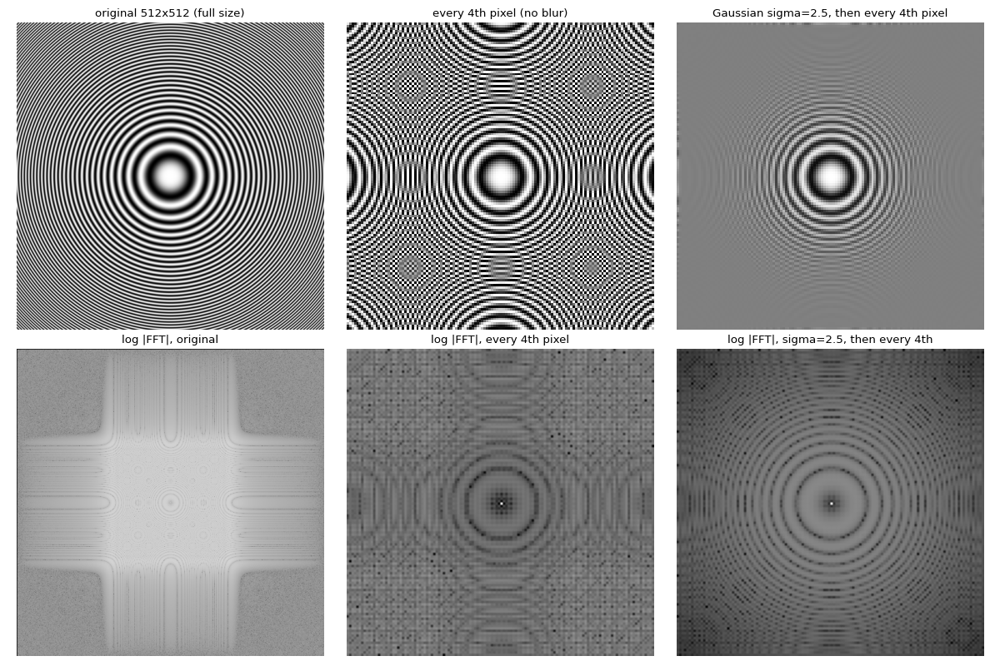

In [ ]:
SIGMA_ALIAS = 2.5          # <- smallest sigma at which you no longer see false circles (look at the sweep first)
if RUN["aliasing_2_2"] and have(IMG + "/part2_frequencies/rings.png"):
    run_script("run_2_2_aliasing.py", SIGMA_ALIAS)
    show_png("fig_2_2_sigma_sweep.png", "fig_2_2_side_by_side.png")

### 2.3 Gaussian and Laplacian pyramids

image (670, 736, 3) (sides are not powers of 2)
level  Gaussian shape     pixels   Laplacian shape
  0    (670, 736)         493120   (670, 736)
  1    (335, 368)         123280   (335, 368)
  2    (168, 184)          30912   (168, 184)
  3    (84, 92)             7728   (84, 92)
  4    (42, 46)             1932   (42, 46)
  5    (21, 23)              483   (21, 23)
total pixels in the Gaussian pyramid / image = 657455/493120 = 1.33326  (4/3 = 1.33333); Laplacian pyramid has the same sizes -> same total
Laplacian display: 0.5 + 1.99 * L  (99.5th percentile of |L| over levels 0..4 is 0.2514), clipped to [0, 1]

REBUILD (ours): shape (670, 736, 3); max|error| = 1.665e-16; RMSE = 1.994e-18; exactly zero in 99.6% of the values
        8-bit-quantized input: max|error| = 2.220e-16
REBUILD ('level minus its blur', Lecture-3 style as I understand it): max|error| = 0.2673; RMSE = 0.0492

ALIASING LEFT BY reduce():  one reduce keeps every 2nd pixel, new Nyquist = 0.25 cycles/px; kernel response

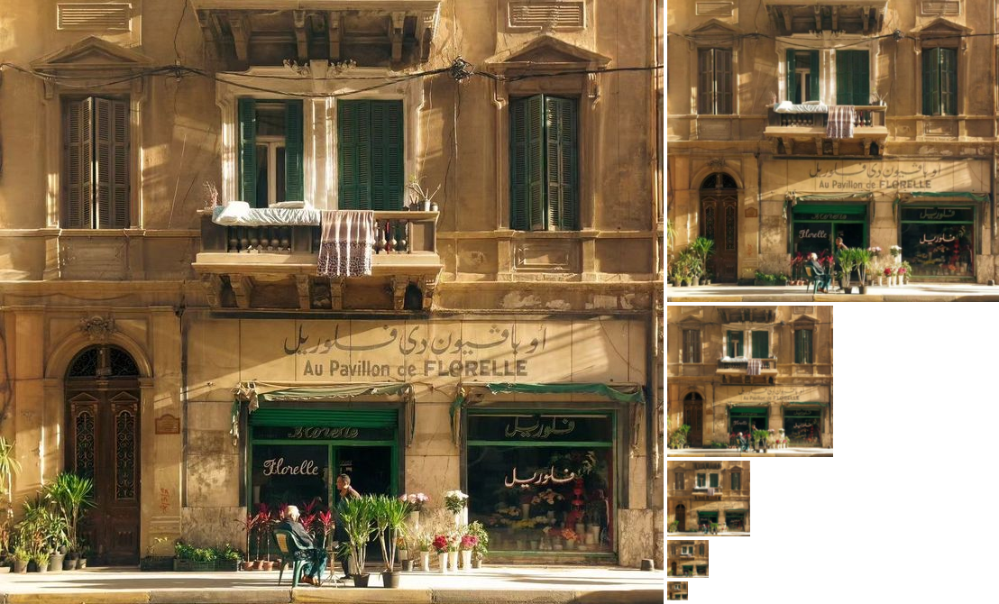

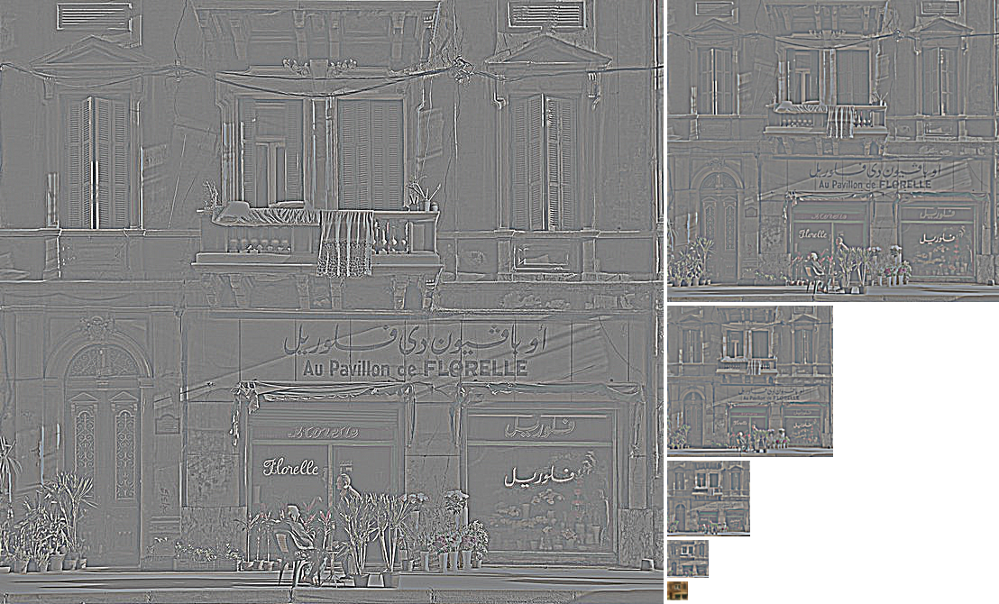

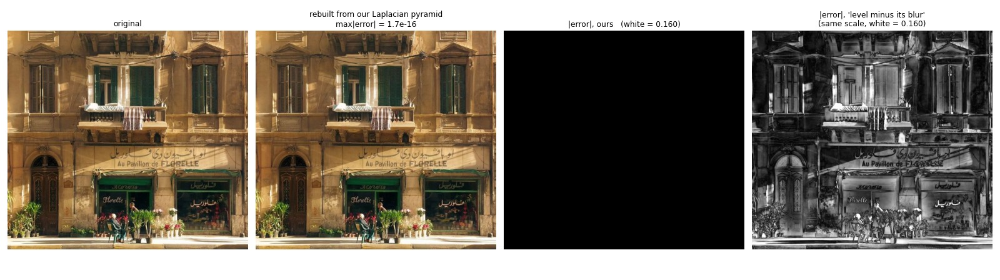

In [ ]:
if RUN["pyramids_2_3"] and have(IMG + "/part1_filters/facade.png", IMG + "/part2_frequencies/rings.png"):
    run_script("run_2_3_pyramids.py")
    show_png("fig_2_3_gaussian_pyramid.png", "fig_2_3_laplacian_pyramid.png", "fig_2_3_reconstruction.png")

### 2.4 Multiresolution blending
`base` is the background image (it defines the size), `obj` is the image pasted on it (warped onto `base` with two points on each). The mask is a filled polygon in **base** coordinates (white = show `obj`). Fill the **OWN** entries.

In [ ]:
# check the kite mask polygons by eye (adjust the vertices in the next cell until they hug the kite)
KITE_BODY = [(329, 92), (405, 103), (374, 193), (295, 157)]
KITE_TAIL = [(378, 200), (392, 228), (420, 260), (455, 282), (487, 300), (480, 310),
             (445, 298), (415, 278), (395, 255), (380, 230), (372, 205)]
from utils import load_image, show
chk = load_image(OWN_FILES["blend2_obj"]).copy()
for P in (KITE_BODY, KITE_TAIL):
    cv2.polylines(chk, [np.array(P, np.int32)], True, (1, 0, 0), 1)
show(chk, size=8)
# to choose where the kite goes on the clouds:  grid(OWN_FILES["blend2_base"])


c:\Users\W.I\Desktop\cv_assignment1\code\utils.py:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


[oraple] 6 levels; blend range [-0.000, 1.000], 0.00% of values clipped for display/saving


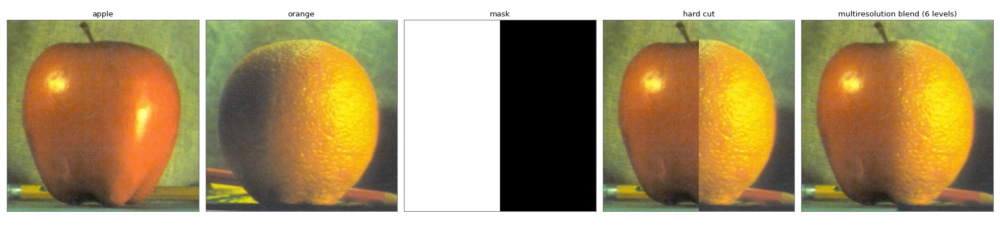

[own1] 5 levels; blend range [-0.003, 1.000], 3.37% of values clipped for display/saving


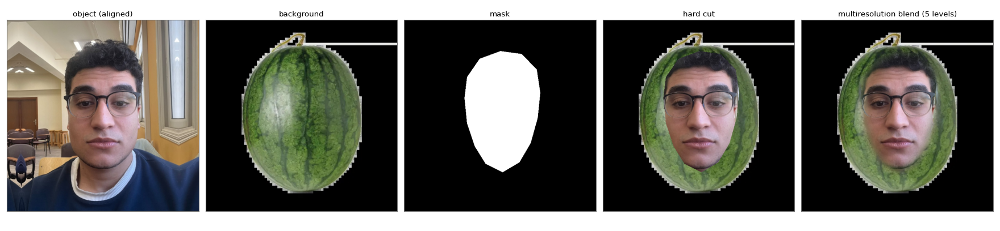

[own1] level-by-level figure: Laplacian levels shown as 0.5 + 1.90 * x, clipped to [0, 1]


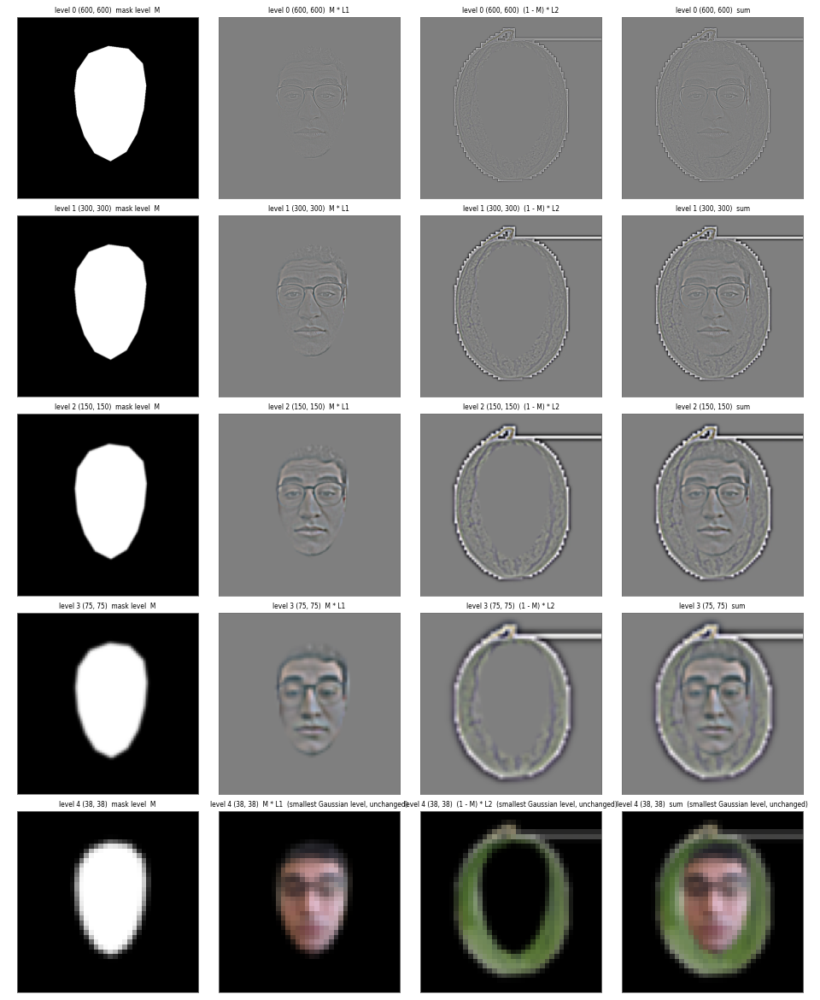

[own2] 3 levels; blend range [-0.042, 1.066], 0.05% of values clipped for display/saving


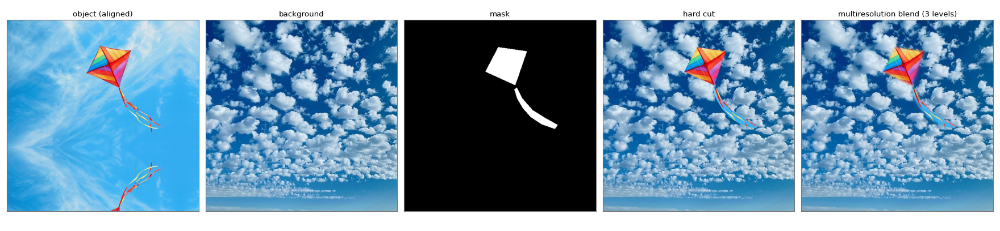

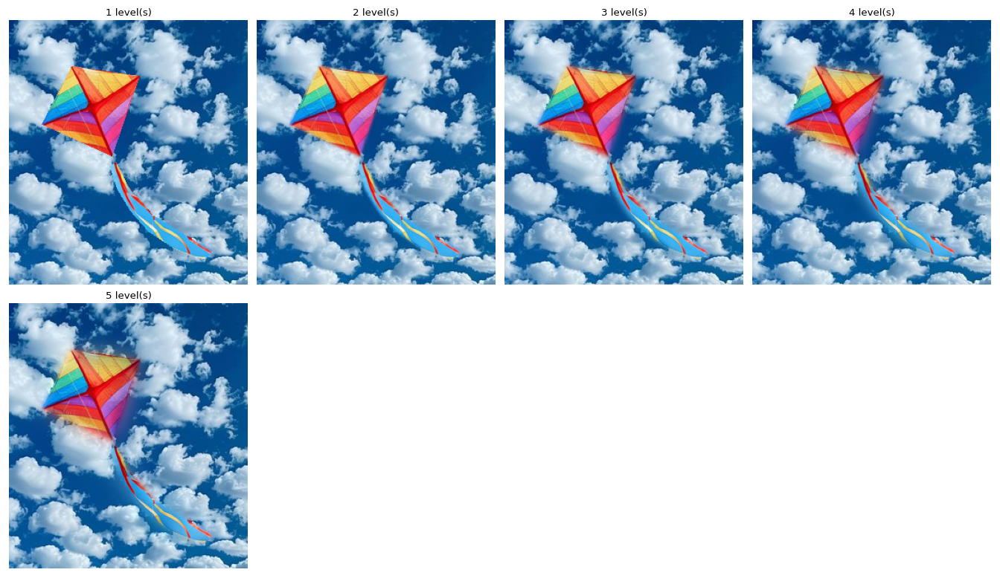

In [ ]:
from run_2_4_blending import blend_pair, level_by_level, depth_sweep
from utils import load_image
from align_images import align_images, similarity_from_two_points

D2 = IMG + "/part2_frequencies/"

# Kite mask: two polygons drawn on the KITE image, then warped with the same transform as the image.
KITE_BODY = [(329, 92), (405, 103), (374, 193), (295, 157)]
KITE_TAIL = [(378, 200), (392, 228), (420, 260), (455, 282), (487, 300), (480, 310),
             (445, 298), (415, 278), (395, 255), (380, 230), (372, 205)]

BLENDS = [  # pts_base / pts_obj: two matching points
            # poly     : mask vertices in BASE coordinates (own1)
            # poly_obj : polygons in OBJECT coordinates, warped with the alignment transform (own2)
    # own1: face (eyes) on the watermelon; irregular face-shaped mask (14 vertices)
    dict(name="own1", base=OWN_FILES["blend1_base"], obj=OWN_FILES["blend1_obj"],
         pts_base=[(245, 265), (355, 265)], pts_obj=[(310, 452), (477, 455)],
         poly=[(301, 98), (367, 107), (414, 155), (425, 228), (417, 307), (395, 386), (360, 446), (308, 477),
               (255, 451), (221, 396), (197, 324), (189, 245), (197, 179), (236, 122)],
         poly_obj=None, levels=5, favorite=True),
    # own2: the kite in the sky; pts_obj = top and bottom tip of the kite, pts_base keeps the same offsets (48, 107) -> scale 1.0
    dict(name="own2", base=OWN_FILES["blend2_base"], obj=OWN_FILES["blend2_obj"],
         pts_base=[(250, 70), (298, 177)], pts_obj=[(328, 89), (376, 196)],
         poly=None, poly_obj=[KITE_BODY, KITE_TAIL], levels=3, favorite=False),
]
if RUN["blends_2_4"]:
    # --- oraple: apple (left half of the mask = white) + orange
    if have(D2+"apple.jpg", D2+"orange.jpg"):
        apple, orange = load_image(D2+"apple.jpg").astype(np.float64), load_image(D2+"orange.jpg").astype(np.float64)
        m = np.zeros(apple.shape[:2]); m[:, :apple.shape[1] // 2] = 1.0
        blend_pair("oraple", apple, orange, m, 6, ("apple", "orange"))
        show_png("fig_2_4_oraple.png")
    # --- own blends
    for b in BLENDS:
        if b["pts_base"] is None or b["pts_obj"] is None or (b["poly"] is None and b["poly_obj"] is None):
            print(f"[{b['name']}] SKIPPED - set pts_base, pts_obj and poly / poly_obj first"); continue
        if not have(b["base"], b["obj"]): continue
        base = load_image(b["base"]).astype(np.float64)
        obj_raw = load_image(b["obj"])
        obj = align_images(base, obj_raw, b["pts_base"], b["pts_obj"]).astype(np.float64)
        if b["poly"] is not None:                                      # polygon in BASE coordinates
            m = np.zeros(base.shape[:2], np.uint8)
            cv2.fillPoly(m, [np.array(b["poly"], np.int32)], 1)        # sharp mask; its Gaussian pyramid softens it
        else:                                                          # polygons drawn on the object, then warped
            mo = np.zeros(obj_raw.shape[:2], np.uint8)
            for P in b["poly_obj"]:
                cv2.fillPoly(mo, [np.array(P, np.int32)], 1)
            M = similarity_from_two_points(b["pts_obj"], b["pts_base"])
            m = cv2.warpAffine(mo, M, (base.shape[1], base.shape[0]), flags=cv2.INTER_NEAREST)
        m = m.astype(np.float64)
        blend_pair(b["name"], obj, base, m, b["levels"], ("object (aligned)", "background"))
        show_png(f"fig_2_4_{b['name']}.png")
        if b["name"] == "own2":                                        # use this to choose the number of levels
            depth_sweep("own2", obj, base, m, [1, 2, 3, 4, 5], (slice(20, 320), slice(180, 450)))
            show_png("fig_2_4_own2_depth.png")
        if b["favorite"]:
            level_by_level(b["name"], obj, base, m, b["levels"])
            show_png(f"fig_2_4_{b['name']}_levels.png")


## Part 3 - Seam carving
### 3.1 Energy and removed seams (30% of the width)

broadway_tower (484, 714, 3); removing 214 seams = 30.0% of the width -> 500 columns
possible vertical seams: between 10^148 and 10^233;  DP work per seam: H*W*3 = 1,036,728 comparisons
finite-difference energy: 33.1 s for 214 seams (155 ms per seam incl. energy recompute); result (484, 500, 3)
mean energy per seam pixel: first seam 0.0084, last seam 0.0188, image mean energy 0.0530

PADDING OF THE ENERGY:  zero (as in 1.2)  vs  reflect
  zeros   : energy on the 1-px frame = 0.459 (interior mean 0.053); seam pixels in the 5 leftmost / rightmost columns: 1717 of 103576; mean seam energy 0.0166
  reflect : energy on the 1-px frame = 0.025 (interior mean 0.053); seam pixels in the 5 leftmost / rightmost columns: 2565 of 103576; mean seam energy 0.0148


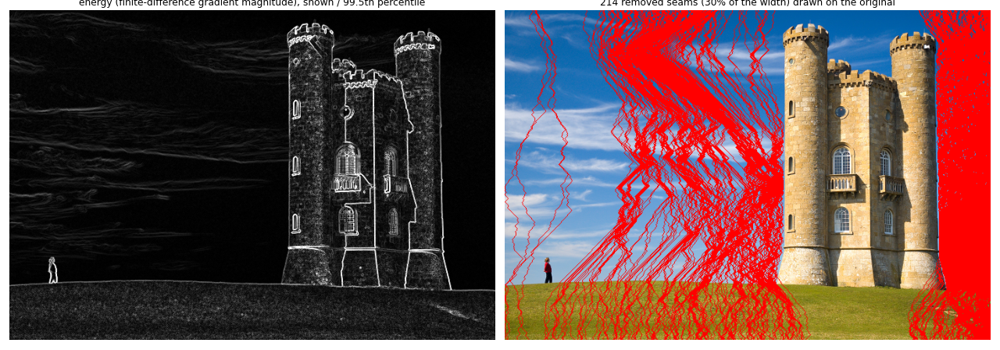

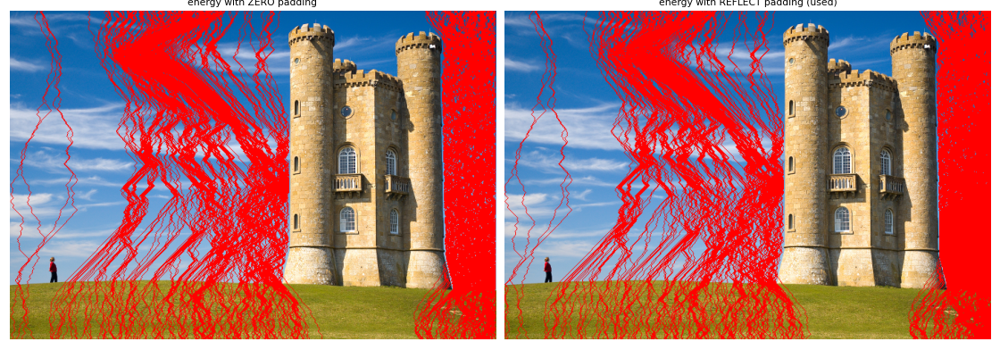

In [ ]:
if RUN["seams_3_1"] and have(IMG + "/part3_seams/broadway_tower.png"):
    run_script("run_3_1_seams.py")
    show_png("fig_3_1_energy_and_seams.png", "fig_3_1_padding_comparison.png")

### 3.2 Seam carving vs resizing vs center crop (two energy functions)
Starter images + your three own images. Mark which one is the failure case in your report.

[rocket] 640x427 -> width 448 (192 seams, 66 s for both energies) | mean seam energy / image mean energy: FD 0.13 (last seam 0.20), DoG 0.22 (last 0.29) | FD/DoG removed-pixel overlap (Jaccard) 0.43


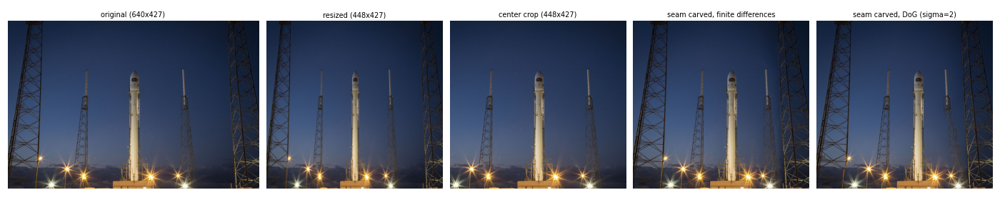

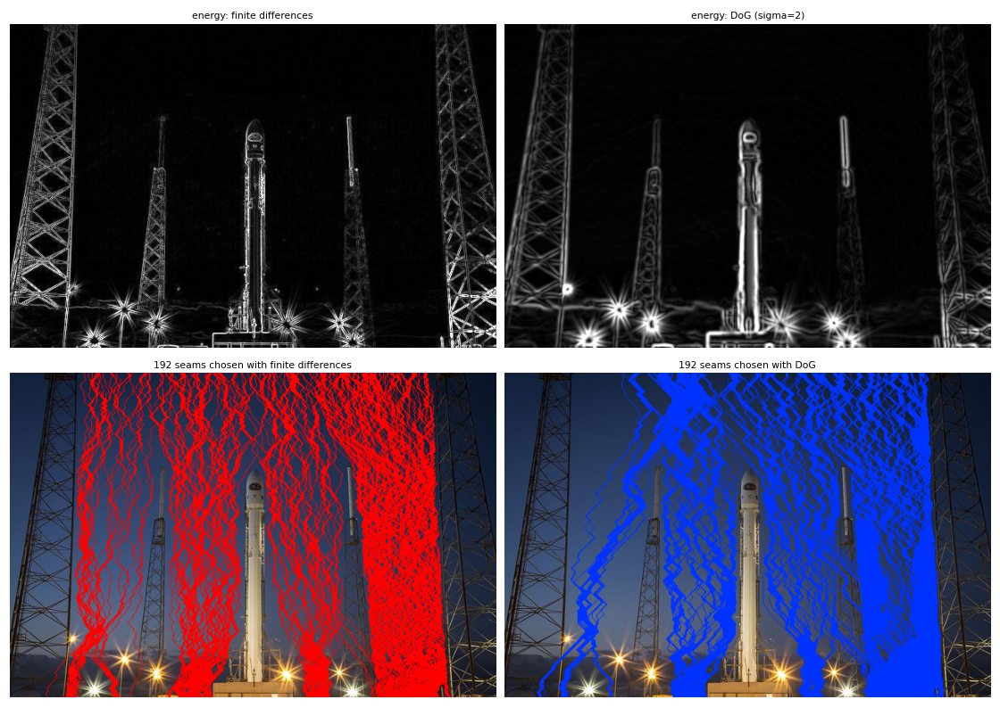

[home] 512x384 -> width 358 (154 seams, 35 s for both energies) | mean seam energy / image mean energy: FD 0.15 (last seam 0.33), DoG 0.21 (last 0.36) | FD/DoG removed-pixel overlap (Jaccard) 0.53


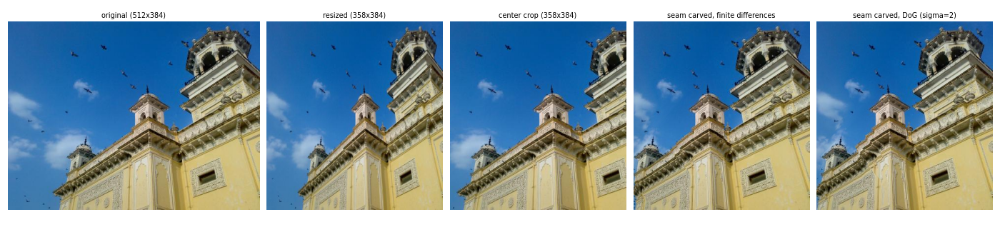

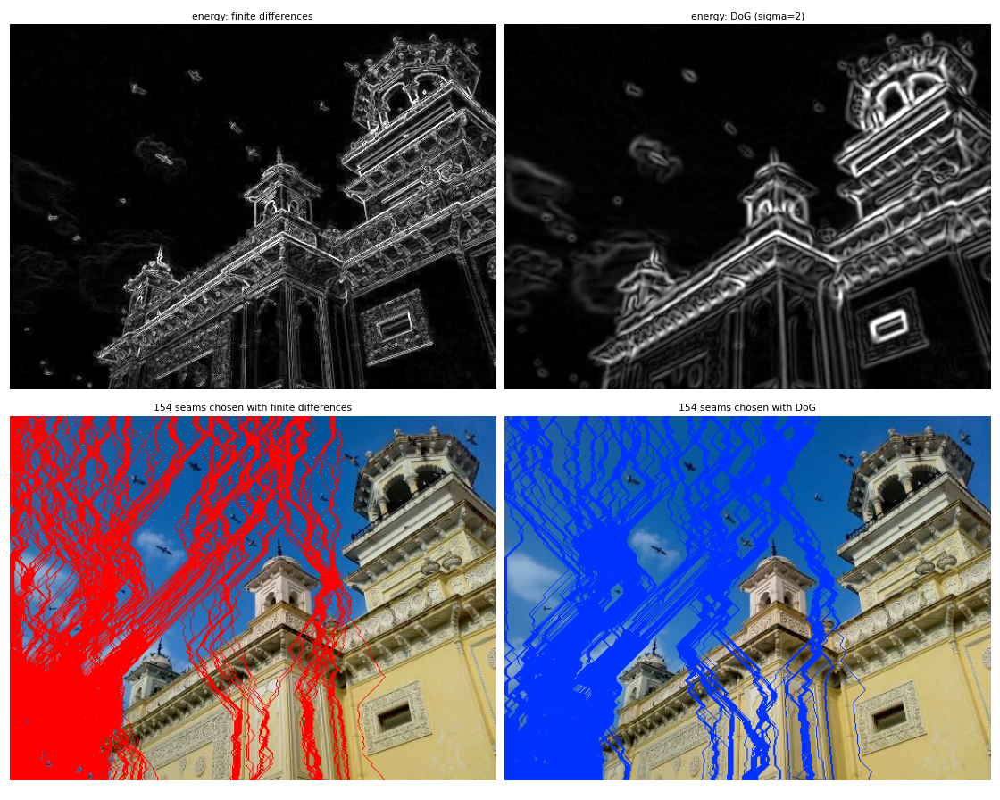

[starry_night] 720x568 -> width 504 (216 seams, 98 s for both energies) | mean seam energy / image mean energy: FD 0.45 (last seam 0.54), DoG 0.40 (last 0.50) | FD/DoG removed-pixel overlap (Jaccard) 0.36


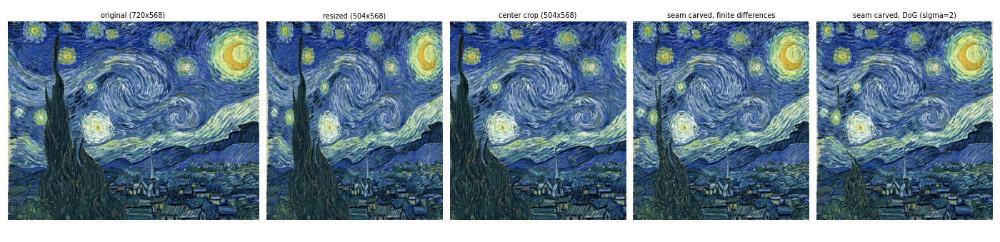

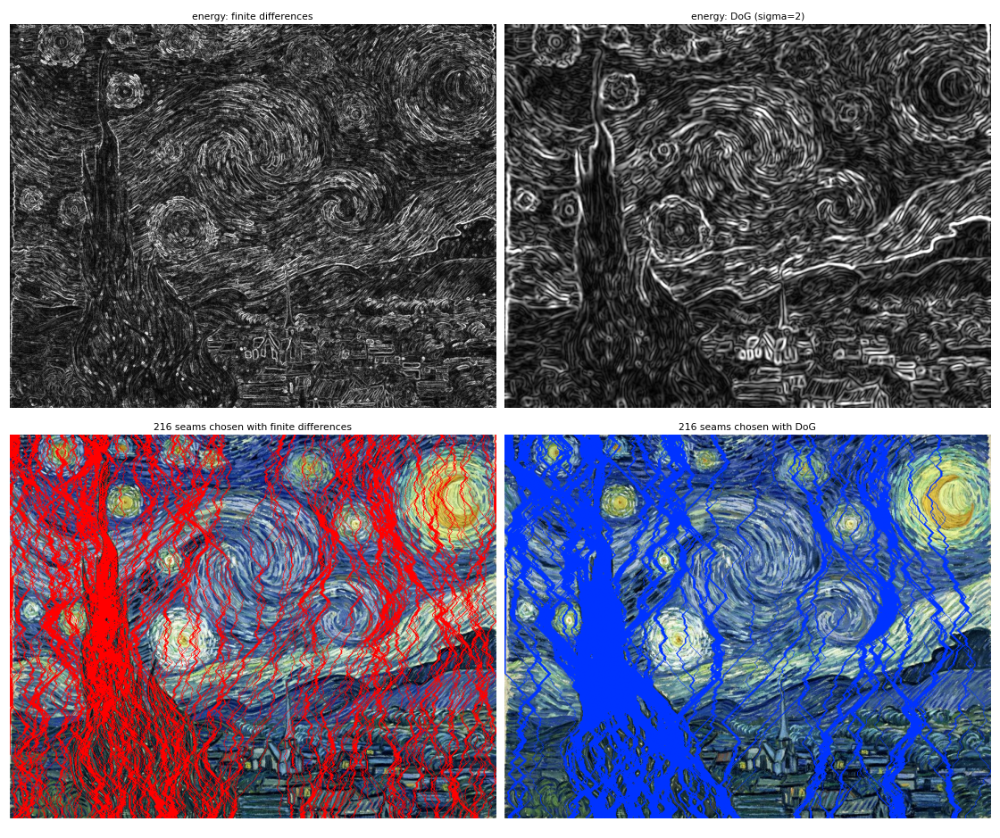

[own_person] 612x407 -> width 428 (184 seams, 59 s for both energies) | mean seam energy / image mean energy: FD 0.58 (last seam 0.66), DoG 0.55 (last 0.61) | FD/DoG removed-pixel overlap (Jaccard) 0.34


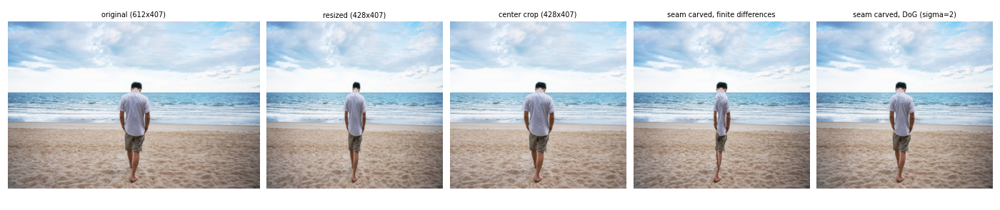

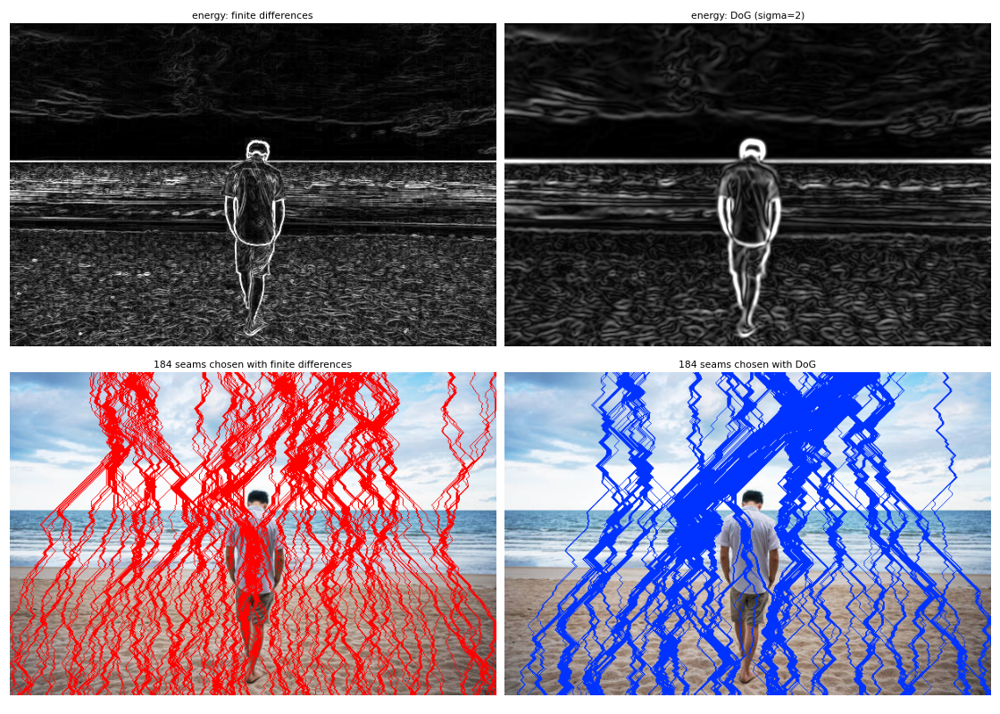

[own_landscape] 626x468 -> width 438 (188 seams, 60 s for both energies) | mean seam energy / image mean energy: FD 0.63 (last seam 0.70), DoG 0.69 (last 0.76) | FD/DoG removed-pixel overlap (Jaccard) 0.32


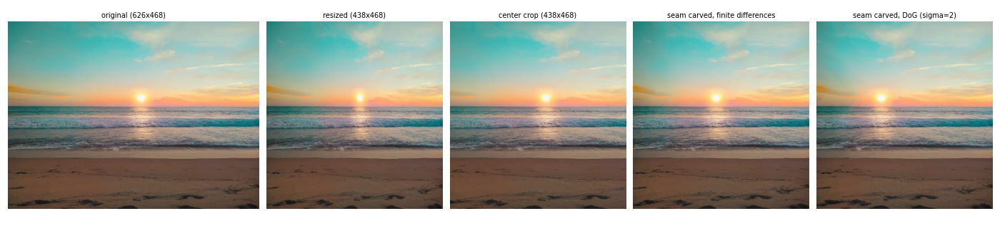

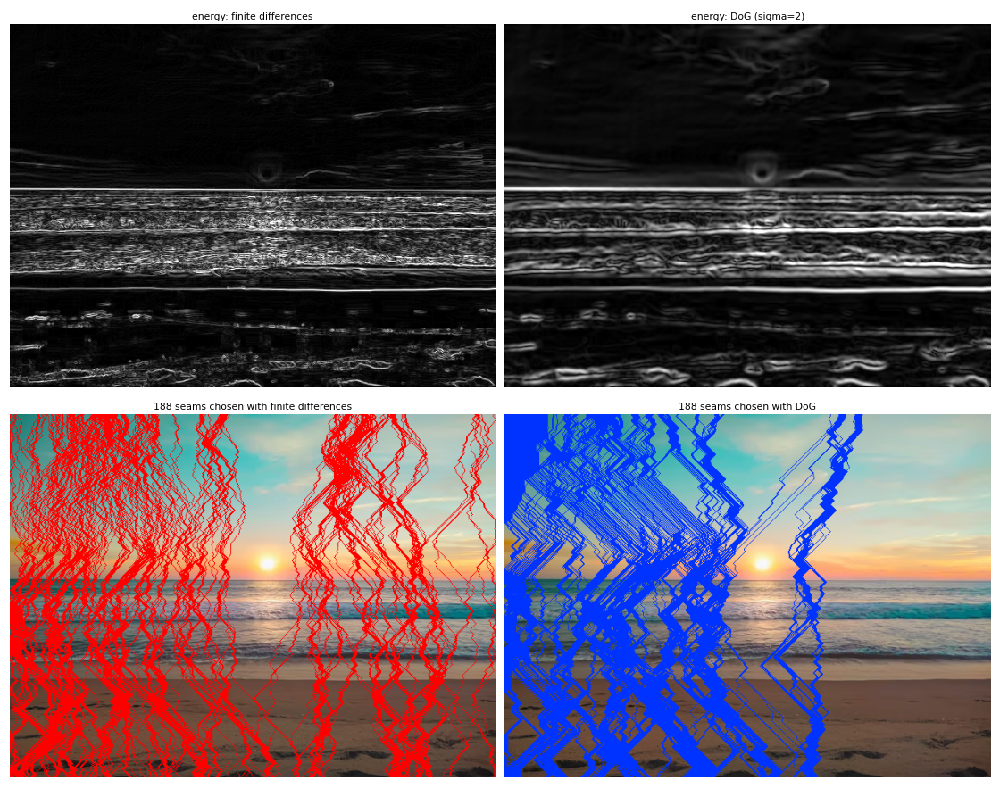

[own_fail] 1000x562 -> width 700 (300 seams, 175 s for both energies) | mean seam energy / image mean energy: FD 0.27 (last seam 0.35), DoG 0.30 (last 0.39) | FD/DoG removed-pixel overlap (Jaccard) 0.59


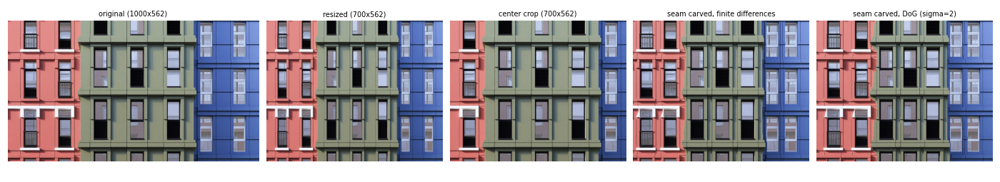

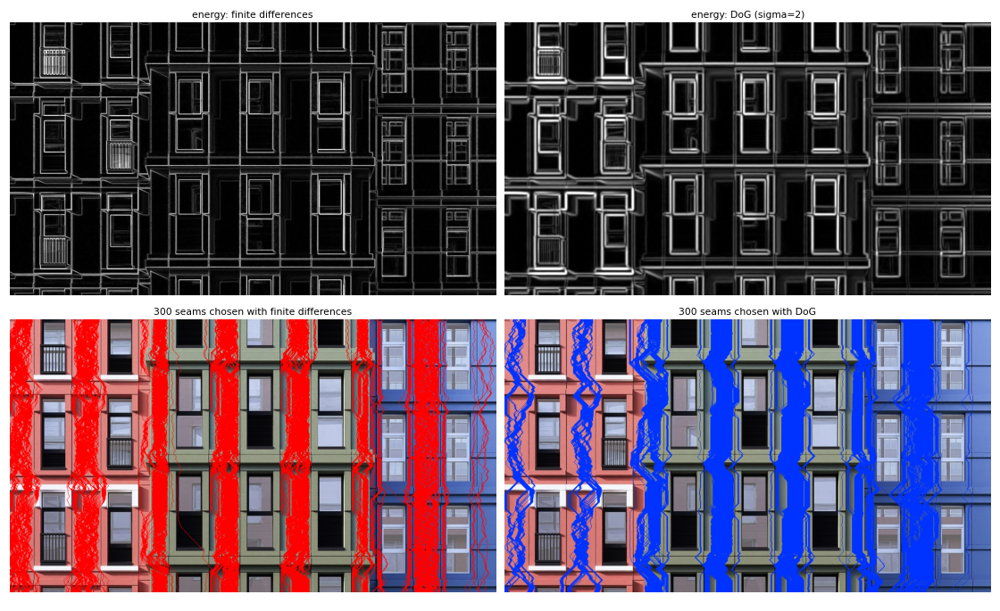

In [ ]:
from run_3_2_comparisons import compare
D3 = IMG + "/part3_seams/"
STARTER_3_2 = [("rocket", D3+"rocket.jpg"), ("home", D3+"home.jpg"), ("starry_night", D3+"starry_night.jpg")]
OWN_3_2 = [("own_person", OWN_FILES["seam_person"]), ("own_landscape", OWN_FILES["seam_landscape"]), ("own_fail", OWN_FILES["seam_fail"])]
STATS = {}
if RUN["compare_3_2"]:
    for name, path in STARTER_3_2 + OWN_3_2:
        if not have(path): continue
        STATS[name], _ = compare(name, load_image(path).astype(np.float64))
        show_png(f"fig_3_2_{name}_compare.png", f"fig_3_2_{name}_seams.png")

#### 3.2 failure case on a starter image (starry_night, DoG energy)

[starry_night] 720x568 -> width 504 (216 seams, 95 s for both energies) | mean seam energy / image mean energy: FD 0.45 (last seam 0.54), DoG 0.40 (last 0.50) | FD/DoG removed-pixel overlap (Jaccard) 0.36
cypress proxy (gray < 0.22, columns < 330): 59913 px = 14.7% of the image
  finite differences  : removed 54.0% of the cypress pixels (a uniform 30% resize would remove 30.0%); 26.3% of ALL removed pixels lie on the cypress
      row 350: cypress width 75 px -> 21 px  (x0.28)
      row 420: cypress width 171 px -> 96 px  (x0.56)
      row 500: cypress width 197 px -> 99 px  (x0.50)
  DoG (sigma=2)       : removed 64.4% of the cypress pixels (a uniform 30% resize would remove 30.0%); 31.4% of ALL removed pixels lie on the cypress
      row 350: cypress width 75 px -> 1 px  (x0.01)
      row 420: cypress width 171 px -> 76 px  (x0.44)
      row 500: cypress width 197 px -> 77 px  (x0.39)
saved fig_3_2_failure_starry_night.png


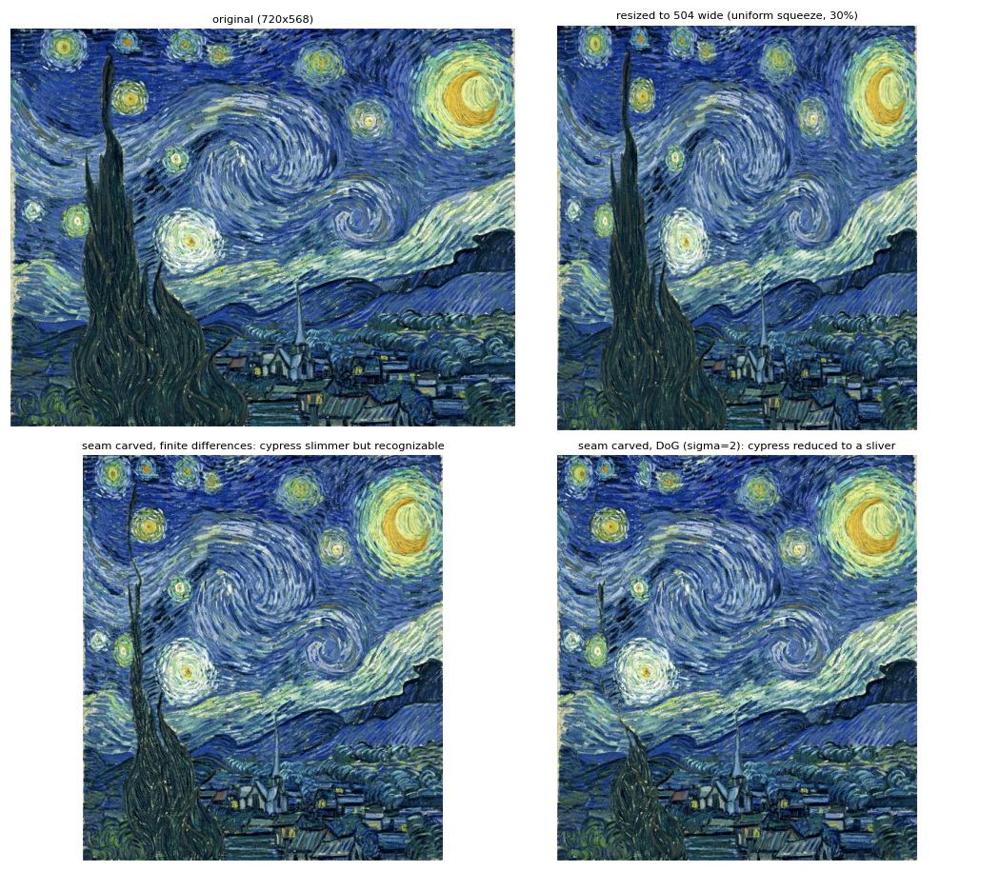

In [ ]:
if RUN["compare_3_2"] and have(IMG + "/part3_seams/starry_night.jpg"):
    run_script("run_3_2_failure_analysis.py")
    show_png("fig_3_2_failure_starry_night.png")

## Bonus - remove an object, then grow the photo back by inserting seams
**OWN:** `poly` = vertices of a polygon around the object (use `grid(...)`), in image coordinates.

[own] 612x459; mask 39886 px, widest row 125 px -> k = 125 seams removed (14.4 s), reduced to width 487; grown back by 125 seams (10.7 s) -> width 612
[own] how often a pixel of the reduced photo is written: k seams from a copy -> at most 2x (57375 pixels written twice, 0 more than twice); cheapest seam inserted 125 times -> up to 126x (1658 duplicated, 1556 more than twice)
[own] distinct columns of the reduced photo that get stretched (mean over rows): k-from-copy 125.0, repeated-cheapest 3.6  (of k = 125)


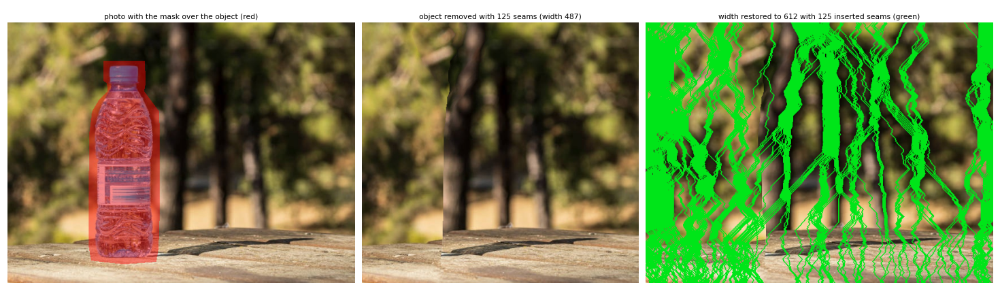

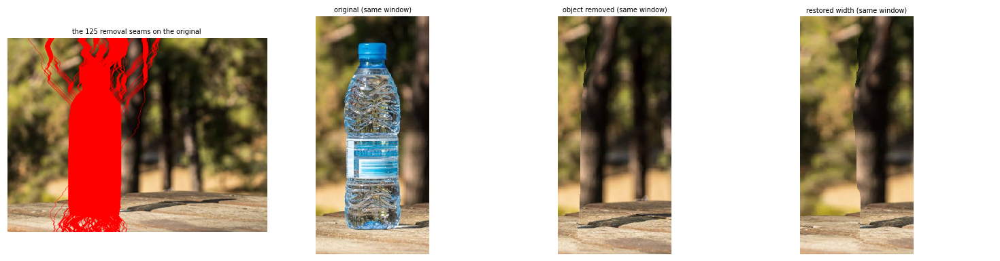

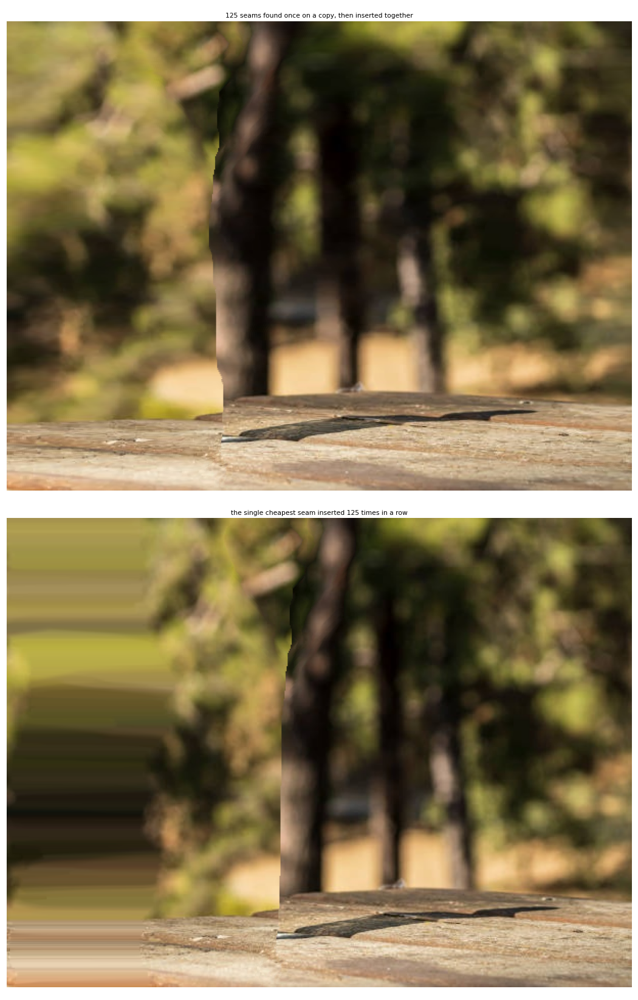

In [ ]:
from run_bonus import object_removal_pipeline
BONUS = dict(name="own", path=OWN_FILES["bonus_photo"],      # the water bottle
             poly=[(172, 72), (238, 72), (239, 105), (236, 124), (248, 140), (263, 160), (264, 200), (264, 330), (262, 396),
                   (258, 418), (205, 422), (150, 416), (146, 390), (146, 330), (147, 200), (152, 160), (164, 140),
                   (180, 124), (178, 105), (172, 100)])
if RUN["bonus"]:
    if BONUS["poly"] is None:
        print("SKIPPED - set BONUS['poly'] (polygon around the object) first")
    elif have(BONUS["path"]):
        photo = load_image(BONUS["path"]).astype(np.float64)
        mk = np.zeros(photo.shape[:2], np.uint8)
        cv2.fillPoly(mk, [np.array(BONUS["poly"], np.int32)], 1)         # sharp mask, drawn in code
        mk = cv2.dilate(mk, np.ones((3, 3), np.uint8), iterations=3)    # grow the mask ~3 px: removes the blue speck and the bright streak
        out = object_removal_pipeline(BONUS["name"], photo, mk.astype(np.float64))
        n = BONUS["name"]
        show_png(f"fig_bonus_{n}.png", f"fig_bonus_{n}_zoom.png", f"fig_bonus_{n}_naive_vs_copy.png")

---
All figures are saved in `../results`. Use them (and the numbers printed above) in the report PDF.